# 2. Clustering y perfiles socioeducativos

Ajusta KMeans y GMM, compara k2–6, calcula estabilidad y una ablación de acceso. La etiqueta y sus ramas no se utilizan para formar ni seleccionar grupos.

In [1]:
from pathlib import Path
import os,sys,json,subprocess,time
import pandas as pd
from IPython.display import display,Image,Markdown
ROOT=Path.cwd()
if not (ROOT/'src').is_dir(): ROOT=ROOT.parent
assert (ROOT/'src/run_analysis.py').exists(), 'Abra el notebook dentro del proyecto'
os.environ['MPLCONFIGDIR']=str(ROOT/'tmp/matplotlib')
os.environ['XDG_CACHE_HOME']=str(ROOT/'tmp/cache')
sys.path.insert(0,str(ROOT/'src'))
def run_script(name,*args):
    started=time.perf_counter()
    result=subprocess.run([sys.executable,str(ROOT/'src'/name),*map(str,args)],cwd=ROOT,text=True,capture_output=True)
    (ROOT/'reports').mkdir(exist_ok=True)
    (ROOT/'reports'/f'notebook_{name}_{Path(str(args[-1])).name if args else "run"}.log').write_text(result.stdout+result.stderr)
    print(result.stdout[-4500:].replace(str(ROOT),'${PROJECT_ROOT}').replace(str(Path.home()),'${HOME}'))
    if result.returncode: print(result.stderr); result.check_returncode()
    print(f'Ejecución real completada en {time.perf_counter()-started:.1f} segundos')
def show(name): display(Image(filename=str(ROOT/'reports/figures'/name)))
def table(name): display(pd.read_csv(ROOT/'reports/tables'/name).head(20))
def results(): return json.loads((ROOT/'reports/results.json').read_text())
print('Python:',sys.version.split()[0], '| kernel del entorno del proyecto')


Python: 3.12.14 | kernel del entorno del proyecto


## Ajuste real en desarrollo
La imputación por mediana y el escalado preceden a la distancia euclidiana/GMM en espacio estandarizado. Silueta usa hasta2500observaciones con semilla42; DB/CH usan desarrollo completo. Se prioriza silueta entre soluciones con todos los grupos de al menos5%.

Cohorte y particiones 13105 3439
Clustering KMeans 2
Clustering KMeans 3
Clustering KMeans 4
Clustering KMeans 5
Clustering KMeans 6
Clustering GMM 2
Clustering GMM 3
Clustering GMM 4
Clustering GMM 5
Clustering GMM 6
Completado clustering CatBoost

Ejecución real completada en 4.6 segundos


,metodo,k,silueta,davies_bouldin,calinski_harabasz,min_proporcion,elegible
0,KMeans,2,0.321677,1.397557,5337.319715,0.378710,True
1,KMeans,3,0.337156,1.147973,4925.571430,0.040977,False
2,KMeans,4,0.354534,0.994546,4980.049850,0.040977,False
3,KMeans,5,0.275625,1.148533,5111.117998,0.040977,False
4,KMeans,6,0.274500,1.140731,4964.826342,0.040900,False
5,GMM,2,0.450995,1.452378,3037.701397,0.096986,True
6,GMM,3,0.265981,1.411482,3893.848338,0.096986,True
7,GMM,4,0.295018,1.120960,3997.843430,0.040977,False
8,GMM,5,0.215129,1.472841,3726.781635,0.040977,False
9,GMM,6,0.195141,1.366416,3402.684154,0.040977,False


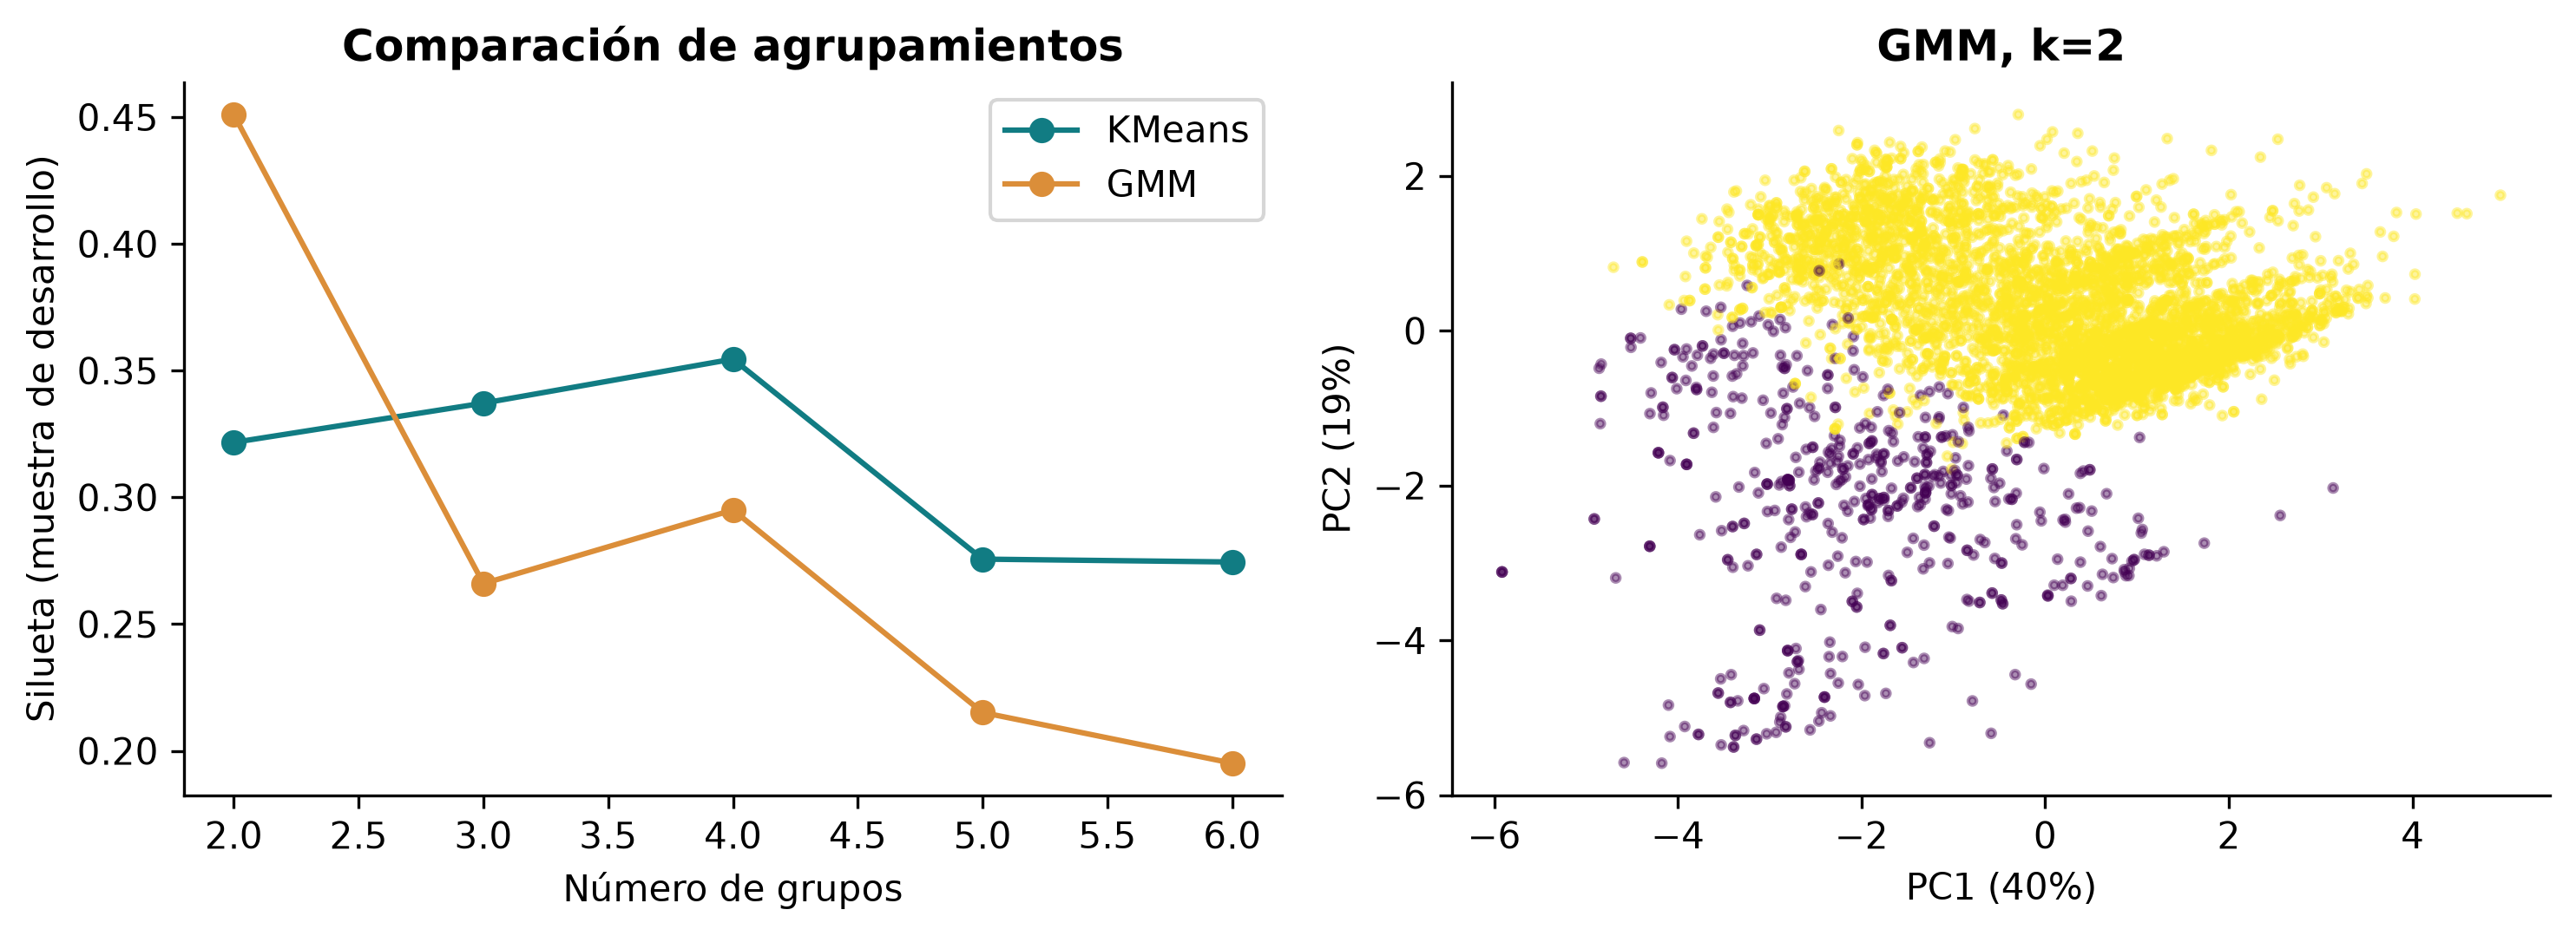

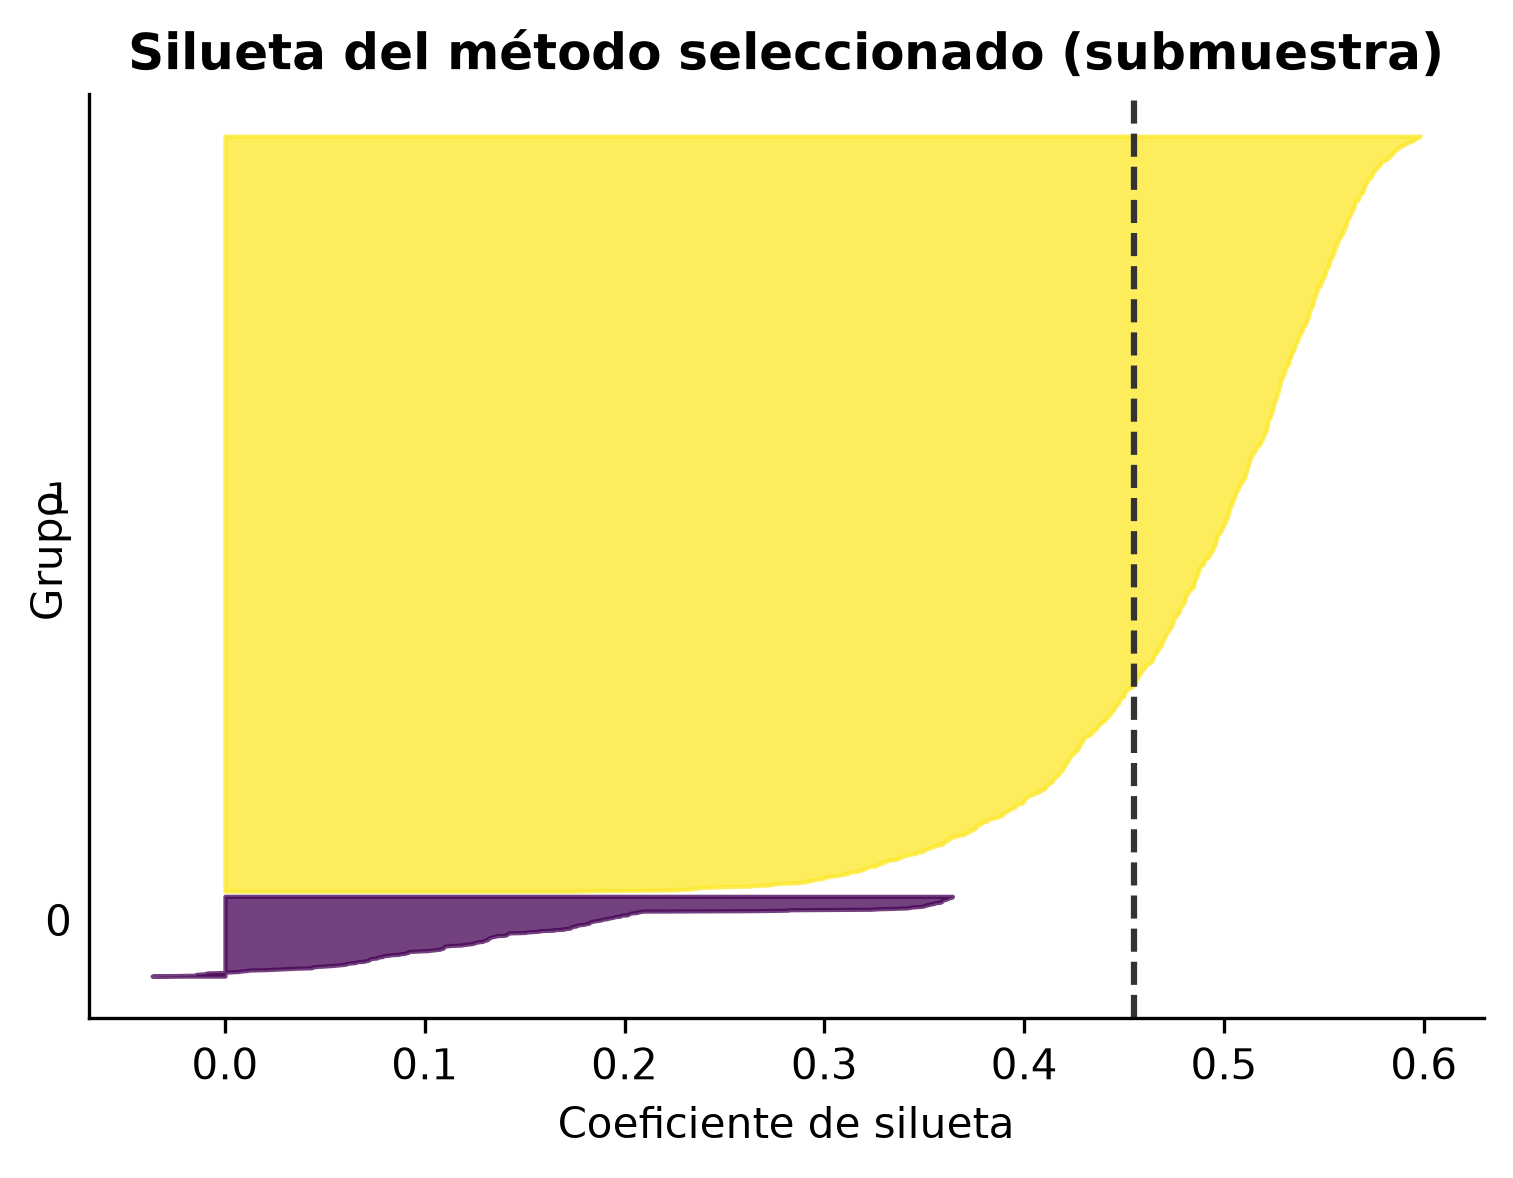

In [2]:
run_script('run_analysis.py','--phase','clustering')
table('clustering_comparison.csv')
show('clustering.png')
show('silhouette.png')

## Estabilidad e interpretación
ARI contrasta asignaciones entre semillas y submuestras80%. La ablación elimina internet/electricidad para medir cuánto depende la separación de esos accesos. La proyección PCA ayuda a visualizar, pero no prueba calidad.

In [3]:
table('clustering_stability.csv')
print(results()['clustering']['access_ablation'])
table('cluster_profiles.csv')

,seed,tipo,ari_vs_seleccion
0,42,semilla,1.0
1,42,submuestra80,1.0
2,43,semilla,1.0
3,43,submuestra80,1.0
4,44,semilla,1.0
5,44,submuestra80,1.0


{'features': ['log_ingreso_pc', 'log_gasto_pc', 'altitud', 'ratio_alumnos_docente', 'prop_publicas'], 'silueta': 0.275104418359942, 'ari_vs_completo': 0.08075259236459058, 'note': 'Mismo metodo y k sin electricidad/internet; diagnostico de dependencia de acceso, no nueva seleccion por etiqueta.'}


,cluster,n,proporcion,no_uso_ponderado,edad,rural,internet_hogar,electricidad,ingreso_pc_mensual,gasto_pc_mensual,altitud,ratio_alumnos_docente,prop_publicas,prop_pobreza,prop_castellano,perfil
0,0,1271,0.096986,0.477435,11.126419,0.589310,0.486262,0.403426,486.282471,474.033284,1411.204470,13.478031,0.773488,0.465266,0.815371,Menor conectividad; rural
1,1,11834,0.903014,0.210705,11.545063,0.182563,1.000000,1.000000,853.471359,704.691680,1170.147264,15.922129,0.539919,0.307014,0.955153,Mayor conectividad; urbano


## Conclusión
Describa tamaños, condiciones del hogar, lengua, pobreza y contexto escolar a partir de la tabla. Las tasas de no uso se incorporan solo para caracterización posterior. Las medias de perfil están ponderadas; el ajuste y las métricas geométricas no. Los grupos son perfiles estadísticos exploratorios, no categorías causales.